# 03 · Líneas base y modelos candidatos

Todos los modelos usan **la misma preparación** (`construir_pipeline`), **la misma validación** (StratifiedKFold de 5 pliegues, semilla 42, solo sobre el entrenamiento) y **la misma métrica técnica** (AUC-ROC). Además se registra la *average precision*, que es más sensible a la clase minoritaria.

Cada corrida queda en MLflow con:
- **Parámetros:** hiperparámetros y semilla.
- **Datos:** tabla de origen, fecha de corte y hash del dataset.
- **Métricas:** entrenamiento, media y desviación de la CV, brecha y segundos.
- **Tags:** fase, familia y commit de Git.
- **Artefacto:** el pipeline ajustado, con su firma y un ejemplo de entrada.

In [1]:
import sys, os, time, json, warnings
sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, mlflow
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from src.datos import cargar_obt, dividir, SEMILLA
from src.pipeline import construir_pipeline, pipeline_regla
from src import tracking
sns.set_theme(style='whitegrid'); IMG = '../docs/img/'
print('MLflow:', tracking.configurar())
obt, meta = cargar_obt()
X_train, X_test, y_train, y_test = dividir(obt)
cols = list(X_train.columns); resultados = []
meta

2026/11/18 20:10:00 INFO mlflow.tracking.fluent: Experiment with name 'anticipar-mora' does not exist. Creating a new experiment.


MLflow: http://localhost:5001


{'tabla_origen': 'PSET2_MORA.OBT.OBT_CUSTOMER_DEFAULT',
 'fecha_corte_snapshot': '2005-09-30',
 'fecha_extraccion': '2026-11-18T22:22:34+00:00',
 'hash_dataset': '372bafd08cb627ae',
 'n_filas': 30000,
 'n_columnas': 53}

## 1. Líneas base
1. **Ingenua:** `DummyClassifier(strategy='prior')` predice la tasa de impago para todos (AUC = 0,5).
2. **De negocio (PSet 1):** riesgo = 1 si el cliente tiene ≥ 1 mes de atraso en el último estado de cuenta.

In [2]:
resultados.append(tracking.correr('baseline_dummy', 'baseline', 'dummy',
    construir_pipeline(DummyClassifier(strategy='prior'), cols), X_train, y_train, meta))
resultados.append(tracking.correr('baseline_regla_negocio', 'baseline', 'regla_negocio',
    pipeline_regla(), X_train, y_train, meta, params={'regla': 'pay_status_m1 >= 1'}))
pd.DataFrame(resultados)[['modelo','train_roc_auc','cv_roc_auc_mean','cv_roc_auc_std','cv_average_precision_mean']].round(4)

2026/11/18 20:10:10 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:10:12 INFO mlflow.tracking._tracking_service.client: 🏃 View run baseline_dummy at: http://localhost:5001/#/experiments/1/runs/7dae2997be9f4638bd9efad7592cd50f.


2026/11/18 20:10:12 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


2026/11/18 20:10:17 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:10:18 INFO mlflow.tracking._tracking_service.client: 🏃 View run baseline_regla_negocio at: http://localhost:5001/#/experiments/1/runs/d1927662a6bc4df28312536a2beecb55.


2026/11/18 20:10:18 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


,modelo,train_roc_auc,cv_roc_auc_mean,cv_roc_auc_std,cv_average_precision_mean
0,baseline_dummy,0.5000,0.5000,0.0000,0.2212
1,baseline_regla_negocio,0.6879,0.6879,0.0054,0.3688


## 2. Candidatos con hiperparámetros por defecto

Solo fijo la semilla y, donde aplica, `n_jobs`. Son cinco familias: lineal regularizado, bagging, boosting (tres implementaciones), red neuronal y un modelo fundacional (LLM, en la sección 4).

In [3]:
candidatos = {
    'logistic_regression': ('lineal_regularizado', LogisticRegression(max_iter=1000, random_state=SEMILLA)),
    'random_forest':       ('bagging',  RandomForestClassifier(random_state=SEMILLA, n_jobs=-1)),
    'hist_gradient_boosting': ('boosting', HistGradientBoostingClassifier(random_state=SEMILLA)),
    'lightgbm':            ('boosting', LGBMClassifier(random_state=SEMILLA, verbose=-1, n_jobs=-1)),
    'xgboost':             ('boosting', XGBClassifier(random_state=SEMILLA, n_jobs=-1, eval_metric='logloss')),
    'mlp':                 ('red_neuronal', MLPClassifier(random_state=SEMILLA)),
}
LR_DEFAULT = {'hist_gradient_boosting': 0.1, 'lightgbm': 0.1, 'xgboost': 0.3, 'mlp': 0.001}
for nombre, (familia, modelo) in candidatos.items():
    r = tracking.correr(nombre, 'candidato', familia, construir_pipeline(modelo, cols), X_train, y_train, meta)
    resultados.append(r); print(f"{nombre:24s} CV AUC {r['cv_roc_auc_mean']:.4f} ± {r['cv_roc_auc_std']:.4f} | train {r['train_roc_auc']:.4f} | {r['cv_seconds_total']:.0f}s")

2026/11/18 20:10:26 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:10:27 INFO mlflow.tracking._tracking_service.client: 🏃 View run logistic_regression at: http://localhost:5001/#/experiments/1/runs/ffb1a69cbf364dac8a49ae6cd8efe111.


2026/11/18 20:10:27 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


logistic_regression      CV AUC 0.7806 ± 0.0066 | train 0.7853 | 2s


2026/11/18 20:10:41 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:10:42 INFO mlflow.tracking._tracking_service.client: 🏃 View run random_forest at: http://localhost:5001/#/experiments/1/runs/2347a8b434864b9b9f2e4264781c1e4f.


... (14 outputs left out)

2026/11/18 20:12:40 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/18 20:12:40 INFO mlflow.tracking._tracking_service.client: 🏃 View run mlp at: http://localhost:5001/#/experiments/1/runs/f19cd788efbb440c8ea289ebfb3866f3.


2026/11/18 20:12:40 INFO mlflow.tracking._tracking_service.client: 🧪 View experiment at: http://localhost:5001/#/experiments/1.


mlp                      CV AUC 0.7464 ± 0.0062 | train 0.8844 | 70s


## 3. Comparación y diagnóstico de sobreajuste

In [4]:
res = pd.DataFrame(resultados)
res['learning_rate'] = res.modelo.map(LR_DEFAULT)
tabla = res[['modelo','familia','fase','train_roc_auc','cv_roc_auc_mean','cv_roc_auc_std','brecha_roc_auc',
             'cv_average_precision_mean','learning_rate','fit_seconds_mean','train_seconds','run_id']].sort_values('cv_roc_auc_mean', ascending=False)
regla = res.set_index('modelo').loc['baseline_regla_negocio','cv_roc_auc_mean']
tabla['supera_regla'] = tabla.cv_roc_auc_mean > regla
tabla.to_csv('../docs/resultados_candidatos.csv', index=False)
tabla.round(4)

,modelo,familia,fase,train_roc_auc,cv_roc_auc_mean,cv_roc_auc_std,brecha_roc_auc,cv_average_precision_mean,learning_rate,fit_seconds_mean,train_seconds,run_id,supera_regla
4,hist_gradient_boosting,boosting,candidato,0.8596,0.7842,0.0044,0.0754,0.5632,0.100,0.4631,0.7339,ec817b29f81e405e997f3076ac97cef5,True
5,lightgbm,boosting,candidato,0.9046,0.7822,0.0068,0.1223,0.5569,0.100,0.5311,0.5681,69b7cc89110a4cc9836643a1a8562763,True
2,logistic_regression,lineal_regularizado,candidato,0.7853,0.7806,0.0066,0.0047,0.5505,NaN,0.2776,0.3439,ffb1a69cbf364dac8a49ae6cd8efe111,True
6,xgboost,boosting,candidato,0.9694,0.7662,0.0064,0.2032,0.5321,0.300,0.2858,0.3099,84d1fe4ba25741f0b4538a6db7c30f29,True
3,random_forest,bagging,candidato,1.0000,0.7632,0.0033,0.2367,0.5345,NaN,1.3830,1.6690,2347a8b434864b9b9f2e4264781c1e4f,True
7,mlp,red_neuronal,candidato,0.8844,0.7464,0.0062,0.1381,0.4994,0.001,13.8895,17.4453,f19cd788efbb440c8ea289ebfb3866f3,True
1,baseline_regla_negocio,regla_negocio,baseline,0.6879,0.6879,0.0054,-0.0000,0.3688,NaN,0.0021,0.0001,d1927662a6bc4df28312536a2beecb55,False
0,baseline_dummy,dummy,baseline,0.5000,0.5000,0.0000,0.0000,0.2212,NaN,0.0705,0.0882,7dae2997be9f4638bd9efad7592cd50f,False


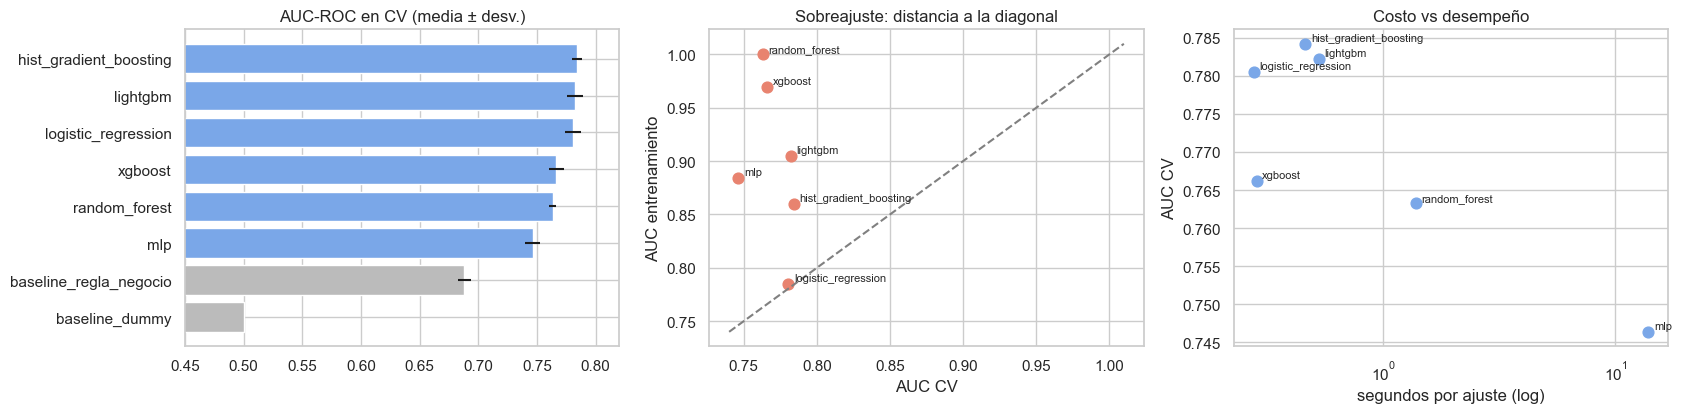

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.3))
t = tabla.sort_values('cv_roc_auc_mean')
col = ['#bbbbbb' if f=='baseline' else '#7aa7e8' for f in t.fase]
ax[0].barh(t.modelo, t.cv_roc_auc_mean, xerr=t.cv_roc_auc_std, color=col); ax[0].set_xlim(0.45, 0.82); ax[0].set_title('AUC-ROC en CV (media ± desv.)')
c = t[t.fase=='candidato']
ax[1].scatter(c.cv_roc_auc_mean, c.train_roc_auc, s=60, color='#e8836f')
for _, r in c.iterrows(): ax[1].annotate(r.modelo, (r.cv_roc_auc_mean, r.train_roc_auc), fontsize=8, xytext=(4,2), textcoords='offset points')
lims = [0.74, 1.01]; ax[1].plot(lims, lims, '--', c='gray'); ax[1].set_xlabel('AUC CV'); ax[1].set_ylabel('AUC entrenamiento'); ax[1].set_title('Sobreajuste: distancia a la diagonal')
ax[2].scatter(c.fit_seconds_mean, c.cv_roc_auc_mean, s=60, color='#7aa7e8'); ax[2].set_xscale('log')
for _, r in c.iterrows(): ax[2].annotate(r.modelo, (r.fit_seconds_mean, r.cv_roc_auc_mean), fontsize=8, xytext=(4,2), textcoords='offset points')
ax[2].set_xlabel('segundos por ajuste (log)'); ax[2].set_ylabel('AUC CV'); ax[2].set_title('Costo vs desempeño')
plt.tight_layout(); plt.savefig(IMG+'candidatos.png', dpi=150); plt.show()

## 4. Modelo fundacional: LLM por prompting

**Planteamiento:** cada cliente se serializa como texto con su cupo, su edad, su historial de 6 meses de estados, saldos y pagos, y sus agregados. Se le pide al LLM una probabilidad de impago entre 0 y 1, con unos pocos ejemplos etiquetados (*few-shot*) del propio entrenamiento.

**Evaluación justa:** se usa una muestra estratificada de 200 clientes del **entrenamiento** (el hold-out no se toca). Sobre esos mismos 200 clientes se compara la AUC del LLM con la del mejor modelo tabular, calculada con predicciones *out-of-fold*. Se usa una muestra porque cada cliente es una llamada a la API, con su costo y su latencia; con 24.000 clientes por pliegue, la CV completa no es viable.

Requiere `ANTHROPIC_API_KEY` en `.env`. Si no está, la celda lo informa y no registra ninguna corrida falsa.

In [6]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict, train_test_split
from concurrent.futures import ThreadPoolExecutor

def describir(r):
    hist = '; '.join(f"{m}: estado {int(r[f'pay_status_m{i}'])}, saldo {r[f'bill_amt_m{i}']:.0f}, pago {r[f'pay_amt_m{i}']:.0f}"
                     for i, m in zip(range(1,7), ['sep','ago','jul','jun','may','abr']))
    return (f"cupo {r.limit_bal:.0f} NT$, edad {int(r.age)}, educación {int(r.education_code)}, "
            f"máx. atraso 6m {int(r.max_delay_6m)}, meses en mora 6m {int(r.n_delinquent_months_6m)}, "
            f"utilización media {r.avg_utilization_6m:.2f}. Historial (estado: -2 sin consumo, -1 pago total, 0 pago mínimo, k = k meses de atraso): {hist}")

KEY = os.environ.get('ANTHROPIC_API_KEY')
if not KEY:
    print('ANTHROPIC_API_KEY no configurada: el LLM no se ejecutó en esta corrida (ver README para habilitarlo).')
else:
    import anthropic
    cliente = anthropic.Anthropic(); MODELO_LLM = os.environ.get('LLM_MODEL', 'claude-haiku-5-5')
    idx_rest, idx_s = train_test_split(np.arange(len(X_train)), test_size=200, stratify=y_train, random_state=SEMILLA)
    shots = X_train.iloc[idx_rest].groupby(y_train.iloc[idx_rest].values).head(3)
    ejemplos = '\n'.join(f"Cliente: {describir(r)}\nImpago en octubre: {'sí' if y_train.loc[i] else 'no'}" for i, r in shots.iterrows())
    sistema = ('Eres analista de riesgo de tarjetas de crédito en Taiwán (2005). Estima la probabilidad de que el cliente '
               'NO pague su próxima cuota (octubre). La tasa base de impago es 22%. Responde solo con JSON: {"p": <número entre 0 y 1>}.')
    def preguntar(r):
        for intento in range(3):
            try:
                m = cliente.messages.create(model=MODELO_LLM, max_tokens=20, temperature=0, system=sistema,
                        messages=[{'role':'user','content': f"Ejemplos:\n{ejemplos}\n\nCliente: {describir(r)}\nProbabilidad de impago:"}])
                return float(json.loads(m.content[0].text.strip().strip('`').replace('json',''))['p'])
            except Exception as e:
                time.sleep(2*(intento+1))
        return np.nan
    t0 = time.perf_counter()
    with ThreadPoolExecutor(8) as ex: p_llm = np.array(list(ex.map(preguntar, [r for _, r in X_train.iloc[idx_s].iterrows()])))
    seg = time.perf_counter() - t0; ok = ~np.isnan(p_llm); ys = y_train.iloc[idx_s].values
    mejor = tabla[tabla.fase=='candidato'].iloc[0].modelo
    oof = cross_val_predict(construir_pipeline(candidatos[mejor][1], cols), X_train, y_train, cv=5, method='predict_proba')[:, 1]
    auc_llm = roc_auc_score(ys[ok], p_llm[ok]); auc_tab = roc_auc_score(ys[ok], oof[idx_s][ok])
    boot = [roc_auc_score(ys[ok][b], p_llm[ok][b]) for b in [np.random.RandomState(i).choice(ok.sum(), ok.sum()) for i in range(200)] if len(set(ys[ok][b]))==2]
    with mlflow.start_run(run_name='llm_prompting'):
        mlflow.set_tags({'fase':'candidato','familia':'sota_llm','git_commit':tracking.commit_git(),'modelo':'llm_prompting'})
        tracking.log_datos(meta)
        mlflow.log_params({'llm_modelo': MODELO_LLM, 'semilla': SEMILLA, 'n_muestra': int(ok.sum()), 'few_shot': len(shots), 'temperatura': 0})
        mlflow.log_metrics({'cv_roc_auc_mean': auc_llm, 'cv_roc_auc_std': float(np.std(boot)), 'auc_tabular_misma_muestra': auc_tab,
                            'cv_seconds_total': seg, 'segundos_por_cliente': seg/len(idx_s), 'respuestas_validas': ok.mean()})
        mlflow.log_text(sistema + '\n\n' + ejemplos, 'prompt.txt')
    print(f'LLM {MODELO_LLM}: AUC {auc_llm:.3f} ± {np.std(boot):.3f} (bootstrap) en {ok.sum()} clientes | {mejor} en la misma muestra: {auc_tab:.3f} | {seg/len(idx_s):.2f} s/cliente')

ANTHROPIC_API_KEY no configurada: el LLM no se ejecutó en esta corrida (ver README para habilitarlo).


## 5. Lectura de resultados

Los números de la tabla y los gráficos responden tres preguntas:
- **¿Superan a las líneas base?** La columna `supera_regla` compara cada candidato contra la regla de negocio.
- **¿Hay sobreajuste?** Lo indica la `brecha_roc_auc` (AUC de entrenamiento menos AUC de CV). Un modelo con AUC de entrenamiento ≈ 1 y brecha grande memoriza el entrenamiento.
- **¿Cuánto cuesta?** El tiempo de ajuste de cada modelo.

Los 3 mejores por AUC media en CV pasan al tuning (notebook 04). La decisión se toma ahí, leyendo los resultados desde MLflow.